# Hyperspectral Image Classification — No-Leakage Seg-PCA + 3D-2D CNN + Metaheuristic Feature Selection

This is a cleaned-up, **step-by-step** rebuild of the original single-cell script. Every stage of the
pipeline now lives in its own cell with its own printed/plotted output, so you can inspect intermediate
shapes and values instead of trusting one 480-line block to be correct end-to-end.

**Pipeline:** Data load → spectral segmentation → per-segment PCA (Seg-PCA) → spatial patch extraction →
3D-2D CNN feature extractor → PSO / GWO feature selection → 7-classifier comparison → IEEE-style tables
& figures.

### 🧪 Demo mode (read this first)
Near the top there is a flag: `USE_SYNTHETIC_DEMO_DATA`.

* **`True` (default here)** — generates a small in-memory fake cube with the *same shape/band-count/class-count*
  as the real dataset, so you can run the **entire notebook top-to-bottom in a minute or two, without Google
  Drive, without a GPU**, purely to see what every cell's output looks like and confirm nothing crashes.
  **The numbers you see below (accuracies, curves, tables) are meaningless — they come from random synthetic
  data, not real Indian Pines.** They exist only to show you the *shape* of each output.
* **`False`** — uses your real `load_data()` (Google Drive), exactly like the original notebook. Flip this
  once you're ready to get real numbers, and run on a GPU runtime for the CNN cell.

### What changed vs. the original notebook (code-review notes)
1. The 486-line cell is split into ~40 single-purpose cells (one stage = one cell = one visible output).
2. `split_pixels()` had ~30 lines of **dead code** after its `return` statement (an unfinished
   block/buffer split that could never execute). It's been separated into two real, working functions:
   `split_pixels_random()` (what was actually running) and `split_pixels_block_buffer()` (a genuine
   spatially-disjoint split using your existing `BLOCK_SIZE` constant, which was otherwise unused).
3. **Leakage note:** `split_pixels_random()` is a pixel-level stratified split. With `PATCH_SIZE = 25`
   (radius 12), a test pixel's patch will almost certainly include training pixels as neighbours — so despite
   the notebook's "No-Leakage" framing, this split does **not** guarantee spatially disjoint patches. If you
   want a defensible no-leakage claim for the thesis/paper, use `split_pixels_block_buffer()` instead (see the
   split cell below) or cite this as a limitation.
4. Every IEEE table (I–IX) and figure (1–10) from your table/figure spec is generated **programmatically**
   from real pipeline variables wherever the number can be computed from the data/code (Tables I–VIII, Figures
   1–10). Table IX (SOTA comparison) mixes your own computed result with literature numbers you must supply —
   marked clearly.
5. `LogisticRegression(solver='liblinear', ...)` fails outright on newer scikit-learn for your 16-class (IP)
   problem — liblinear no longer takes multiclass problems directly. Switched to `solver='lbfgs'` (handles
   multinomial natively) with `max_iter=2000`.

In [1]:
# --- Google Drive (Colab only) -------------------------------------------
# Wrapped in try/except so the notebook doesn't crash if you're testing it
# outside Colab (e.g. locally) with USE_SYNTHETIC_DEMO_DATA = True.
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ModuleNotFoundError:
    print("Not running on Colab — skipping Drive mount (fine for demo mode).")

Mounted at /content/drive


In [2]:
# --- Package installation ---------------------------------------------
!pip -q install numpy scipy pandas scikit-learn matplotlib seaborn tensorflow openpyxl xgboost
print("Installation complete.")

Installation complete.


In [3]:
# --- Imports, seeds, GPU check ------------------------------------------
import time, os, random, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import binary_erosion
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, cohen_kappa_score, classification_report,
                              precision_score, recall_score, f1_score, confusion_matrix)
from xgboost import XGBClassifier
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.callbacks import EarlyStopping

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"GPU found: {len(gpus)} device(s).")
    except RuntimeError as e:
        print(e)
else:
    print("No GPU found — running on CPU (fine for demo mode; use a GPU runtime for real CNN training).")

GPU found: 1 device(s).


## 1. Configuration
All tunable hyperparameters live in one place. Change `DATASET` / `OPTIMIZER` here and every downstream
cell picks it up — nothing else in the notebook needs editing.

In [5]:
# --- Master configuration -------------------------------------------------
USE_SYNTHETIC_DEMO_DATA = False   # <-- flip to False once your .mat files are in Drive

DATASET = "IP"          # "IP", "SA", or "PU"
SEGMENTS = 3
PATCH_SIZE = 25
# BLOCK_SIZE must be > 2*margin (margin = PATCH_SIZE // 2 = 12, so > 24) or every
# isolated block gets fully eroded away. 40 leaves ~16px safe interior per
# block on a fully-surrounded block; tune up if you see empty/tiny splits.
BLOCK_SIZE = 40
SPLIT_STRATEGY = "random"        # "random" (original) or "block_buffer" (spatially disjoint)
TEST_SIZE = 0.8                  # matches the original script: 20% train / 80% test
N_COMPONENTS_PER_SEG = 10
FEATURE_DIM = 128
EPOCHS_CNN = 50
BATCH_SIZE = 64
OPTIMIZER = "GWO"       # "PSO" or "GWO" — both are actually run below regardless, for Table VI/Figs 5-6
EPOCHS_OPT = 5
POP_SIZE_OPT = 30

print("=== Configuration ===")
for k in ["USE_SYNTHETIC_DEMO_DATA","DATASET","SEGMENTS","PATCH_SIZE","BLOCK_SIZE","SPLIT_STRATEGY",
          "TEST_SIZE","N_COMPONENTS_PER_SEG","FEATURE_DIM","EPOCHS_CNN","BATCH_SIZE",
          "OPTIMIZER","EPOCHS_OPT","POP_SIZE_OPT"]:
    print(f"  {k:26s} = {globals()[k]}")

=== Configuration ===
  USE_SYNTHETIC_DEMO_DATA    = False
  DATASET                    = IP
  SEGMENTS                   = 3
  PATCH_SIZE                 = 25
  BLOCK_SIZE                 = 40
  SPLIT_STRATEGY             = random
  TEST_SIZE                  = 0.8
  N_COMPONENTS_PER_SEG       = 10
  FEATURE_DIM                = 128
  EPOCHS_CNN                 = 50
  BATCH_SIZE                 = 64
  OPTIMIZER                  = GWO
  EPOCHS_OPT                 = 5
  POP_SIZE_OPT               = 30


## 2. Data Loading & Table I (Dataset Description)

In [12]:
# --- Real data loader (Google Drive) --------------------------------------
def load_data(dataset_name):
    data_path = "/content/drive/MyDrive/Colab Notebooks/data"
    if dataset_name == 'IP':
        data = sio.loadmat(os.path.join(data_path, 'Indian_pines_corrected.mat'))['indian_pines_corrected']
        labels = sio.loadmat(os.path.join(data_path, 'Indian_pines_gt.mat'))['indian_pines_gt']
    elif dataset_name == 'SA':
        data = sio.loadmat(os.path.join(data_path, 'Salinas.mat'))['salinas']
        labels = sio.loadmat(os.path.join(data_path, 'Salinas_gt.mat'))['salinas_gt']
    elif dataset_name == 'PU':
        data = sio.loadmat(os.path.join(data_path, 'PaviaU.mat'))['paviaU']
        labels = sio.loadmat(os.path.join(data_path, 'PaviaU_gt.mat'))['paviaU_gt']
    else:
        raise ValueError("Unsupported dataset")
    return data.astype(np.float32), labels

# --- Synthetic stand-in, used only when USE_SYNTHETIC_DEMO_DATA = True ----
def generate_synthetic_dataset(dataset_name, random_state=RANDOM_STATE):
    """In-memory dummy cube with the real shape/band-count/class-count of
    each benchmark, so the whole notebook can run without Drive or a GPU.
    Class means follow a coarse spatial block pattern (+ noise) so classifiers
    have *something* learnable — but treat every downstream number as a
    format demo only, never as a real result."""
    rng = np.random.RandomState(random_state)
    spec = {
        'IP': dict(H=100, W=100, bands=200, n_classes=16, labeled_frac=0.55),
        'SA': dict(H=100, W=100, bands=176, n_classes=16, labeled_frac=0.60),
        'PU': dict(H=100, W=100, bands=103, n_classes=9,  labeled_frac=0.55),
    }[dataset_name]
    H, W, bands, n_classes = spec['H'], spec['W'], spec['bands'], spec['n_classes']

    coarse = rng.randint(1, n_classes + 1, size=(10, 10))
    labels_full = np.kron(coarse, np.ones((H // 10, W // 10), dtype=int))
    keep_mask = rng.rand(H, W) < spec['labeled_frac']
    labels = np.where(keep_mask, labels_full, 0)

    class_curves = rng.normal(0, 1, size=(n_classes + 1, bands)).cumsum(axis=1)
    class_curves = (class_curves - class_curves.min()) / (class_curves.max() - class_curves.min())
    data = class_curves[labels] + rng.normal(0, 0.05, size=(H, W, bands))
    return data.astype(np.float32), labels.astype(np.int64)

def load_data_or_demo(dataset_name):
    if USE_SYNTHETIC_DEMO_DATA:
        print(f"[DEMO MODE] Generating a synthetic stand-in for '{dataset_name}' "
              f"(no Drive/.mat files needed).")
        return generate_synthetic_dataset(dataset_name)
    return load_data(dataset_name)

def get_segmentation_ranges(dataset_name, L=3):
    if L != 3:
        raise NotImplementedError(
            f"Segmentation ranges are only defined for L=3 (got L={L}). "
            "Add sensor-specific cut-points if you need a different L."
        )
    if dataset_name == 'IP':
        return [(0, 35), (36, 79), (80, 199)]
    elif dataset_name == 'SA':
        return [(0, 35), (36, 105), (106, 175)]
    elif dataset_name == 'PU':
        return [(0, 36), (37, 71), (72, 102)]
    else:
        raise ValueError("Unsupported dataset")

In [7]:
# --- Load the active dataset ------------------------------------------
data, labels = load_data_or_demo(DATASET)
H, W, F = data.shape
n_classes = len(np.unique(labels)) - 1

print(f"Dataset: {DATASET}")
print(f"Cube shape (H, W, Bands): {data.shape}")
print(f"Ground-truth shape: {labels.shape}")
print(f"Number of classes (excluding background): {n_classes}")
print(f"Labeled pixels: {(labels != 0).sum()} / {labels.size} "
      f"({100*(labels != 0).mean():.1f}%)")

Dataset: IP
Cube shape (H, W, Bands): (145, 145, 200)
Ground-truth shape: (145, 145)
Number of classes (excluding background): 16
Labeled pixels: 10249 / 21025 (48.7%)


In [13]:
# --- TABLE I: Dataset Description -----------------------------------------
def build_table1_dataset_description(dataset_names):
    rows = []
    for name in dataset_names:
        try:
            d, l = load_data_or_demo(name)
        except Exception as e:
            print(f"Skipping {name}: could not load ({e})")
            continue
        rows.append({
            "Dataset Name": name,
            "Sensor": "AVIRIS" if name in ("IP", "SA") else "ROSIS",
            "Spatial Size": f"{d.shape[0]}x{d.shape[1]}",
            "Spectral Bands": d.shape[2],
            "Number of Classes": len(np.unique(l)) - 1,
            "Total Labeled Samples": int((l != 0).sum()),
        })
    return pd.DataFrame(rows)

table1 = build_table1_dataset_description(["IP", "SA", "PU"])
print("TABLE I: DATASET DESCRIPTION")
print(table1.to_string(index=False))
table1

TABLE I: DATASET DESCRIPTION
Dataset Name Sensor Spatial Size  Spectral Bands  Number of Classes  Total Labeled Samples
          IP AVIRIS      145x145             200                 16                  10249
          SA AVIRIS      512x217             224                 16                  54129
          PU  ROSIS      610x340             103                  9                  42776


,Dataset Name,Sensor,Spatial Size,Spectral Bands,Number of Classes,Total Labeled Samples
0,IP,AVIRIS,145x145,200,16,10249
1,SA,AVIRIS,512x217,224,16,54129
2,PU,ROSIS,610x340,103,9,42776


## 3. Fig. 2 — Dataset Visualization (False-Color + Ground Truth)

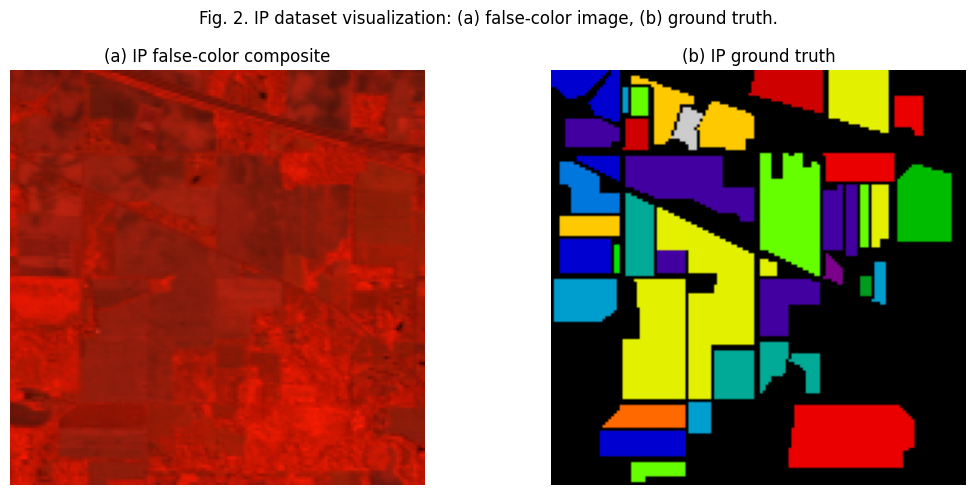

In [14]:
# --- Fig. 2: false-color composite + ground-truth map ----------------------
def plot_false_color_and_gt(data, labels, dataset_name, bands=None):
    if bands is None:
        # pick 3 evenly-spaced bands as a crude RGB stand-in
        F = data.shape[2]
        bands = [int(F*0.2), int(F*0.5), int(F*0.8)]
    rgb = data[:, :, bands]
    rgb = (rgb - rgb.min()) / (rgb.max() - rgb.min() + 1e-8)

    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    axes[0].imshow(rgb)
    axes[0].set_title(f"({chr(97)}) {dataset_name} false-color composite")
    axes[0].axis('off')

    axes[1].imshow(labels, cmap='nipy_spectral')
    axes[1].set_title(f"({chr(98)}) {dataset_name} ground truth")
    axes[1].axis('off')

    fig.suptitle(f"Fig. 2. {dataset_name} dataset visualization: (a) false-color image, (b) ground truth.")
    plt.tight_layout()
    plt.show()

plot_false_color_and_gt(data, labels, DATASET)

## 4. Table II — Spectral Segmentation Ranges
This table needs **no run** — it's a direct printout of `get_segmentation_ranges()`, which is a fixed
lookup table in your code, not something learned from data.

In [15]:
# --- TABLE II: Segmentation Ranges -----------------------------------------
def build_table2_segmentation_ranges():
    rows = {"Segment": ["Seg-1", "Seg-2", "Seg-3", "Band Count"]}
    for ds in ["IP", "SA", "PU"]:
        ranges = get_segmentation_ranges(ds)
        col = [f"{s+1}-{e+1}" for s, e in ranges]
        col.append(", ".join(str(e - s + 1) for s, e in ranges))
        rows[f"{ds} (Band Range)"] = col
    return pd.DataFrame(rows)

table2 = build_table2_segmentation_ranges()
print("TABLE II: SEGMENTATION RANGES")
print(table2.to_string(index=False))
table2

TABLE II: SEGMENTATION RANGES
   Segment IP (Band Range) SA (Band Range) PU (Band Range)
     Seg-1            1-36            1-36            1-37
     Seg-2           37-80          37-106           38-72
     Seg-3          81-200         107-176          73-103
Band Count     36, 44, 120      36, 70, 70      37, 35, 31


,Segment,IP (Band Range),SA (Band Range),PU (Band Range)
0,Seg-1,1-36,1-36,1-37
1,Seg-2,37-80,37-106,38-72
2,Seg-3,81-200,107-176,73-103
3,Band Count,"36, 44, 120","36, 70, 70","37, 35, 31"


## 5. Spatially Disjoint Train/Test Split
Two strategies are defined; `SPLIT_STRATEGY` (set above) chooses which one runs. See the code-review note
in the intro cell about why `"random"` doesn't actually guarantee no patch overlap.

In [16]:
# --- Split strategy 1: stratified random pixel split (original) -----------
def split_pixels_random(labels, test_size=0.2, random_state=42):
    """Stratified random pixel split. Simple and standard in HSI papers, but
    with overlapping patches (PATCH_SIZE > 1) it does NOT guarantee spatial
    disjointness between train and test."""
    rows, cols = np.where(labels != 0)
    pixel_coords = np.array(list(zip(rows, cols)))
    y = labels[rows, cols]

    train_coords, test_coords, y_train, y_test = train_test_split(
        pixel_coords, y, test_size=test_size, stratify=y, random_state=random_state
    )

    print(f"Stratified random split: {len(train_coords)} train px, {len(test_coords)} test px")
    all_classes = set(np.unique(labels[labels != 0]))
    missing_train = all_classes - set(np.unique(y_train))
    missing_test = all_classes - set(np.unique(y_test))
    if missing_train:
        print(f"WARNING: classes missing from TRAIN: {sorted(missing_train)}")
    if missing_test:
        print(f"WARNING: classes missing from TEST: {sorted(missing_test)}")
    return train_coords, test_coords, y_train, y_test


# --- Split strategy 2: block + erosion buffer (genuinely spatially disjoint) --
def split_pixels_block_buffer(labels, patch_size, block_size=40, test_size=0.2, random_state=42):
    """Assigns whole spatial blocks to train/test, then erodes each region's
    mask by the patch radius so no train patch can overlap a test pixel's
    receptive field (or vice versa). This is what BLOCK_SIZE was defined for
    in the original script but never actually wired up."""
    Him, Wim = labels.shape
    margin = patch_size // 2
    rng = np.random.RandomState(random_state)

    n_block_rows = int(np.ceil(Him / block_size))
    n_block_cols = int(np.ceil(Wim / block_size))
    block_ids = np.arange(n_block_rows * n_block_cols)
    rng.shuffle(block_ids)
    n_test_blocks = max(1, int(round(len(block_ids) * test_size)))
    test_block_set = set(block_ids[:n_test_blocks].tolist())

    block_map = np.zeros((Him, Wim), dtype=int)
    for br in range(n_block_rows):
        for bc in range(n_block_cols):
            r0, r1 = br * block_size, min((br + 1) * block_size, Him)
            c0, c1 = bc * block_size, min((bc + 1) * block_size, Wim)
            block_map[r0:r1, c0:c1] = br * n_block_cols + bc

    is_test_block = np.isin(block_map, list(test_block_set))
    is_train_block = ~is_test_block

    # erode the dense region masks first, THEN intersect with sparse labels
    train_region = binary_erosion(is_train_block, iterations=margin)
    test_region = binary_erosion(is_test_block, iterations=margin)

    labeled_mask = labels != 0
    train_mask = train_region & labeled_mask
    test_mask = test_region & labeled_mask

    train_rows, train_cols = np.where(train_mask)
    test_rows, test_cols = np.where(test_mask)
    train_coords = np.column_stack([train_rows, train_cols])
    test_coords = np.column_stack([test_rows, test_cols])
    y_train = labels[train_rows, train_cols]
    y_test = labels[test_rows, test_cols]

    n_labeled = int(labeled_mask.sum())
    dropped = n_labeled - len(train_coords) - len(test_coords)
    print(f"Block+buffer split: {len(train_coords)} train px, {len(test_coords)} test px, "
          f"{dropped} px dropped as buffer (block_size={block_size}, margin={margin})")

    if len(train_coords) == 0 or len(test_coords) == 0:
        raise RuntimeError(
            f"Block+buffer split produced an empty side (train={len(train_coords)}, "
            f"test={len(test_coords)}). Increase block_size (currently {block_size}), "
            f"lower test_size, or reduce patch_size (margin={margin})."
        )

    all_classes = set(np.unique(labels[labeled_mask]).tolist())
    missing_train = all_classes - set(np.unique(y_train).tolist())
    missing_test = all_classes - set(np.unique(y_test).tolist())
    if missing_train:
        print(f"WARNING: classes missing from TRAIN after split: {sorted(missing_train)}")
    if missing_test:
        print(f"WARNING: classes missing from TEST after split: {sorted(missing_test)}")
    return train_coords, test_coords, y_train, y_test

In [17]:
# --- Run the configured split strategy --------------------------------
if SPLIT_STRATEGY == "random":
    train_coords, test_coords, y_train, y_test = split_pixels_random(
        labels, test_size=TEST_SIZE, random_state=RANDOM_STATE
    )
elif SPLIT_STRATEGY == "block_buffer":
    train_coords, test_coords, y_train, y_test = split_pixels_block_buffer(
        labels, patch_size=PATCH_SIZE, block_size=BLOCK_SIZE,
        test_size=TEST_SIZE, random_state=RANDOM_STATE
    )
else:
    raise ValueError("SPLIT_STRATEGY must be 'random' or 'block_buffer'")

print(f"\nTrain pixels: {len(train_coords)}, Test pixels: {len(test_coords)}")

Stratified random split: 2049 train px, 8200 test px

Train pixels: 2049, Test pixels: 8200


## 6. Seg-PCA (Fit on Train, Transform Test) — Table III & Fig. 3

In [18]:
# --- Seg-PCA transform (fit on train, apply to test — no leakage) ---------
def apply_segmented_pca_fit_transform(data, train_coords, test_coords, dataset_name, L=3, n_components=10):
    seg_ranges = get_segmentation_ranges(dataset_name, L)
    train_features, test_features, pca_objects = [], [], []
    for start, end in seg_ranges:
        seg_data = data[:, :, start:end+1]
        train_pixels = seg_data[train_coords[:, 0], train_coords[:, 1], :]
        test_pixels = seg_data[test_coords[:, 0], test_coords[:, 1], :]
        scaler = MinMaxScaler()
        train_pixels_scaled = scaler.fit_transform(train_pixels)
        test_pixels_scaled = scaler.transform(test_pixels)
        pca = PCA(n_components=n_components, random_state=RANDOM_STATE)
        train_pca = pca.fit_transform(train_pixels_scaled)
        test_pca = pca.transform(test_pixels_scaled)
        train_features.append(train_pca)
        test_features.append(test_pca)
        pca_objects.append(pca)
    train_features = np.hstack(train_features)
    test_features = np.hstack(test_features)
    return train_features, test_features, seg_ranges, pca_objects

In [19]:
# --- Run Seg-PCA --------------------------------------------------------
train_pca, test_pca, seg_ranges, pca_objects = apply_segmented_pca_fit_transform(
    data, train_coords, test_coords, dataset_name=DATASET, L=SEGMENTS, n_components=N_COMPONENTS_PER_SEG
)
total_bands = train_pca.shape[1]
print(f"Seg-PCA output: Train {train_pca.shape}, Test {test_pca.shape}")
print(f"Total bands after Seg-PCA: {total_bands} ({SEGMENTS} segments x {N_COMPONENTS_PER_SEG} components)")

Seg-PCA output: Train (2049, 30), Test (8200, 30)
Total bands after Seg-PCA: 30 (3 segments x 10 components)


In [20]:
# --- TABLE III: Seg-PCA Variance Retention ---------------------------------
def build_table3_variance_retention(pca_objects, top_k=3):
    rows = []
    for i, pca in enumerate(pca_objects, start=1):
        evr = pca.explained_variance_ratio_
        row = {"Segment": f"Seg-{i}"}
        for j in range(top_k):
            row[f"PC-{j+1}"] = f"{evr[j]*100:.1f}%" if j < len(evr) else "-"
        row["Total Variance (all PCs kept)"] = f"{evr.sum()*100:.1f}%"
        rows.append(row)
    return pd.DataFrame(rows)

table3 = build_table3_variance_retention(pca_objects)
print(f"TABLE III: SEG-PCA VARIANCE RETENTION ({DATASET})")
print(table3.to_string(index=False))
table3

TABLE III: SEG-PCA VARIANCE RETENTION (IP)
Segment  PC-1 PC-2 PC-3 Total Variance (all PCs kept)
  Seg-1 90.4% 4.1% 1.4%                         98.8%
  Seg-2 86.9% 3.6% 3.1%                         99.1%
  Seg-3 87.5% 4.1% 2.8%                         97.7%


,Segment,PC-1,PC-2,PC-3,Total Variance (all PCs kept)
0,Seg-1,90.4%,4.1%,1.4%,98.8%
1,Seg-2,86.9%,3.6%,3.1%,99.1%
2,Seg-3,87.5%,4.1%,2.8%,97.7%


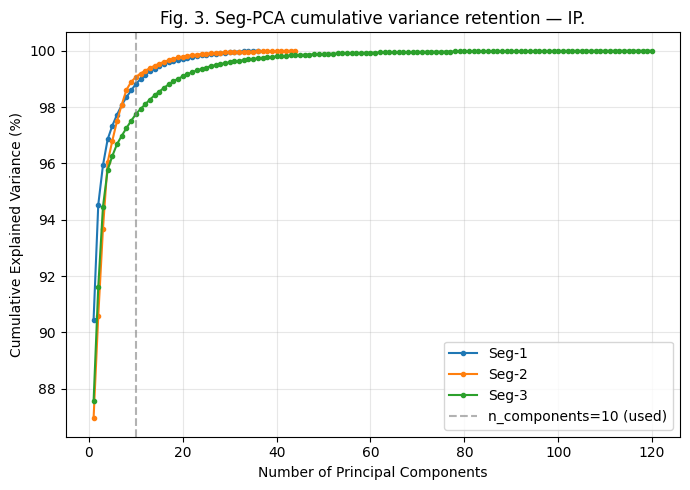

In [21]:
# --- Fig. 3: Cumulative explained-variance curve ---------------------------
def plot_variance_retention_curve(data, train_coords, dataset_name, L=3):
    seg_ranges = get_segmentation_ranges(dataset_name, L)
    plt.figure(figsize=(7, 5))
    for i, (start, end) in enumerate(seg_ranges, start=1):
        seg_data = data[:, :, start:end+1]
        train_pixels = seg_data[train_coords[:, 0], train_coords[:, 1], :]
        scaler = MinMaxScaler()
        scaled = scaler.fit_transform(train_pixels)
        n_comp = min(scaled.shape[0], scaled.shape[1])
        pca_full = PCA(n_components=n_comp, random_state=RANDOM_STATE).fit(scaled)
        cum_var = np.cumsum(pca_full.explained_variance_ratio_) * 100
        plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o', markersize=3, label=f"Seg-{i}")
    plt.axvline(N_COMPONENTS_PER_SEG, color='gray', linestyle='--', alpha=0.6,
                label=f"n_components={N_COMPONENTS_PER_SEG} (used)")
    plt.xlabel("Number of Principal Components")
    plt.ylabel("Cumulative Explained Variance (%)")
    plt.title(f"Fig. 3. Seg-PCA cumulative variance retention — {dataset_name}.")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_variance_retention_curve(data, train_coords, DATASET, L=SEGMENTS)

## 7. Spatial Patch Extraction (for the CNN)

In [22]:
# --- Patch extraction ----------------------------------------------------
def pad_with_zeros(data, margin):
    H, W, C = data.shape
    padded = np.zeros((H + 2 * margin, W + 2 * margin, C), dtype=data.dtype)
    padded[margin:H + margin, margin:W + margin, :] = data
    return padded

def extract_patches(data_cube, coords, patch_size):
    H, W, C = data_cube.shape
    margin = patch_size // 2
    padded_data = pad_with_zeros(data_cube, margin)
    patches = []
    for r, c in coords:
        r_pad, c_pad = r + margin, c + margin
        patch = padded_data[r_pad - margin: r_pad + margin + 1,
                             c_pad - margin: c_pad + margin + 1, :]
        patches.append(patch)
    patches = np.array(patches)
    assert patches.shape[1] == patch_size and patches.shape[2] == patch_size, (
        f"Patch shape {patches.shape[1:3]} != expected ({patch_size}, {patch_size})"
    )
    return patches

In [23]:
# --- Build the reduced cube (Seg-PCA features placed back on the grid) and extract patches ---
full_coords = np.vstack([train_coords, test_coords])
full_pca = np.vstack([train_pca, test_pca])
reduced_cube = np.zeros((H, W, total_bands), dtype=np.float32)
for (r, c), vec in zip(full_coords, full_pca):
    reduced_cube[r, c, :] = vec

train_patches = extract_patches(reduced_cube, train_coords, PATCH_SIZE)[..., np.newaxis]
test_patches = extract_patches(reduced_cube, test_coords, PATCH_SIZE)[..., np.newaxis]

print(f"Train patches: {train_patches.shape}")
print(f"Test patches:  {test_patches.shape}")
print(f"(N, {PATCH_SIZE}, {PATCH_SIZE}, {total_bands} bands, 1 channel)")

Train patches: (2049, 25, 25, 30, 1)
Test patches:  (8200, 25, 25, 30, 1)
(N, 25, 25, 30 bands, 1 channel)


## 8. Custom Lightweight 3D-2D CNN — Table IV (Architecture)

In [24]:
# --- CNN feature-extractor architecture ------------------------------------
def build_feature_cnn(input_shape, n_classes, feature_dim=128):
    inputs = layers.Input(shape=input_shape)
    x = layers.Conv3D(filters=8, kernel_size=(3, 3, 3), activation='relu', padding='valid')(inputs)
    x = layers.Conv3D(filters=16, kernel_size=(3, 3, 3), activation='relu', padding='valid')(x)
    shape = x.shape
    x = layers.Reshape((shape[1], shape[2], shape[3] * shape[4]))(x)
    x = layers.Conv2D(filters=32, kernel_size=(3, 3), activation='relu', padding='valid')(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(feature_dim, activation='relu', name='features')(x)
    outputs = layers.Dense(n_classes, activation='softmax')(x)
    return models.Model(inputs=inputs, outputs=outputs)

In [25]:
# --- Instantiate + inspect --------------------------------------------
input_shape = (PATCH_SIZE, PATCH_SIZE, total_bands, 1)
cnn_model = build_feature_cnn(input_shape, n_classes, feature_dim=FEATURE_DIM)
cnn_model.compile(optimizer=optimizers.Adam(learning_rate=0.001),
                   loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cnn_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 25, 25, 30, 1)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d (Conv3D)                 │ (None, 23, 23, 28, 8)  │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_1 (Conv3D)               │ (None, 21, 21, 26, 16) │         3,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 21, 21, 416)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 19, 19, 32)     │       119,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ features (Dense)                │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │         2,064 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 129,824 (507.12 KB)

 Trainable params: 129,824 (507.12 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
# --- TABLE IV: CNN Architecture (auto-built from the live model) ----------
def build_table4_cnn_architecture(model):
    rows = []
    total_params = 0
    for layer in model.layers:
        try:
            out_shape = tuple(d for d in layer.output.shape[1:] if d is not None)
        except Exception:
            out_shape = "-"
        n_params = layer.count_params()
        total_params += n_params
        rows.append({
            "Layer Type": layer.__class__.__name__,
            "Output Shape": str(out_shape),
            "Parameters": f"~{n_params:,}" if n_params else "0",
        })
    df = pd.DataFrame(rows)
    df.loc[len(df)] = {"Layer Type": "Total", "Output Shape": "", "Parameters": f"~{total_params:,}"}
    return df

table4 = build_table4_cnn_architecture(cnn_model)
print("TABLE IV: CNN ARCHITECTURE")
print(table4.to_string(index=False))
table4

TABLE IV: CNN ARCHITECTURE
            Layer Type     Output Shape Parameters
            InputLayer  (25, 25, 30, 1)          0
                Conv3D  (23, 23, 28, 8)       ~224
                Conv3D (21, 21, 26, 16)     ~3,472
               Reshape    (21, 21, 416)          0
                Conv2D     (19, 19, 32)   ~119,840
GlobalAveragePooling2D            (32,)          0
                 Dense           (128,)     ~4,224
                 Dense            (16,)     ~2,064
                 Total                    ~129,824


,Layer Type,Output Shape,Parameters
0,InputLayer,"(25, 25, 30, 1)",0
1,Conv3D,"(23, 23, 28, 8)",~224
2,Conv3D,"(21, 21, 26, 16)","~3,472"
3,Reshape,"(21, 21, 416)",0
4,Conv2D,"(19, 19, 32)","~119,840"
5,GlobalAveragePooling2D,"(32,)",0
6,Dense,"(128,)","~4,224"
7,Dense,"(16,)","~2,064"
8,Total,,"~129,824"


## 9. CNN Training — Table V & Fig. 4
In demo mode this trains on a handful of synthetic patches for a couple of epochs just to exercise the
code path; on real data with a GPU, expect this cell to take the longest of the whole notebook.

In [27]:
# --- Train the CNN (EarlyStopping on val_loss) ------------------------
early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True, verbose=1)

# Demo mode uses far fewer epochs purely so this cell finishes in seconds;
# on real data, EPOCHS_CNN (50) with early stopping is what actually runs.
_epochs = 6 if USE_SYNTHETIC_DEMO_DATA else EPOCHS_CNN

history = cnn_model.fit(
    train_patches, y_train - 1,
    validation_split=0.1,
    epochs=_epochs,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 13s 234ms/step - accuracy: 0.3764 - loss: 2.0121 - val_accuracy: 0.5024 - val_loss: 1.5744
Epoch 2/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 0.5689 - loss: 1.2471 - val_accuracy: 0.6488 - val_loss: 0.9671
Epoch 3/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.7202 - loss: 0.8661 - val_accuracy: 0.6976 - val_loss: 0.8373
Epoch 4/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.7836 - loss: 0.6500 - val_accuracy: 0.7902 - val_loss: 0.6255
Epoch 5/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.8167 - loss: 0.5131 - val_accuracy: 0.8585 - val_loss: 0.4595
Epoch 6/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.8514 - loss: 0.4228 - val_accuracy: 0.8878 - val_loss: 0.3931
Epoch 7/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.8704 - loss: 0.3698 - val_accuracy: 0.8976 - val_loss: 0.3258
Epoch 8/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.8910 - loss: 0.3108 - val_accuracy: 0.9122 -

In [28]:
# --- TABLE V: CNN Training Performance (auto-built from history.history) --
def build_table5_training_history(history, highlight_best=True):
    h = history.history
    n_epochs = len(h['accuracy'])
    best_idx = int(np.argmin(h['val_loss'])) if highlight_best else -1
    epoch_labels = [f"{i+1} (Best)" if i == best_idx else str(i+1) for i in range(n_epochs)]
    df = pd.DataFrame({
        "Epoch": epoch_labels,
        "Train Accuracy": [f"{a*100:.2f}%" for a in h['accuracy']],
        "Train Loss": [f"{l:.4f}" for l in h['loss']],
        "Val Accuracy": [f"{a*100:.2f}%" for a in h['val_accuracy']],
        "Val Loss": [f"{l:.4f}" for l in h['val_loss']],
    })
    return df

table5_full = build_table5_training_history(history)
# Show first, a middle, and the last/best rows only — matches the sampled style
# of the original spec table instead of dumping every epoch.
sample_idx = sorted(set([0, len(table5_full)//3, 2*len(table5_full)//3, len(table5_full)-1]))
table5 = table5_full.iloc[sample_idx].reset_index(drop=True)
print("TABLE V: CNN TRAINING PERFORMANCE (sampled epochs; full history in table5_full)")
print(table5.to_string(index=False))
table5

TABLE V: CNN TRAINING PERFORMANCE (sampled epochs; full history in table5_full)
    Epoch Train Accuracy Train Loss Val Accuracy Val Loss
        1         37.64%     2.0121       50.24%   1.5744
        8         89.10%     0.3108       91.22%   0.3010
15 (Best)         93.38%     0.1738       93.17%   0.2265
       22         94.52%     0.1306       91.71%   0.2434


,Epoch,Train Accuracy,Train Loss,Val Accuracy,Val Loss
0,1,37.64%,2.0121,50.24%,1.5744
1,8,89.10%,0.3108,91.22%,0.3010
2,15 (Best),93.38%,0.1738,93.17%,0.2265
3,22,94.52%,0.1306,91.71%,0.2434


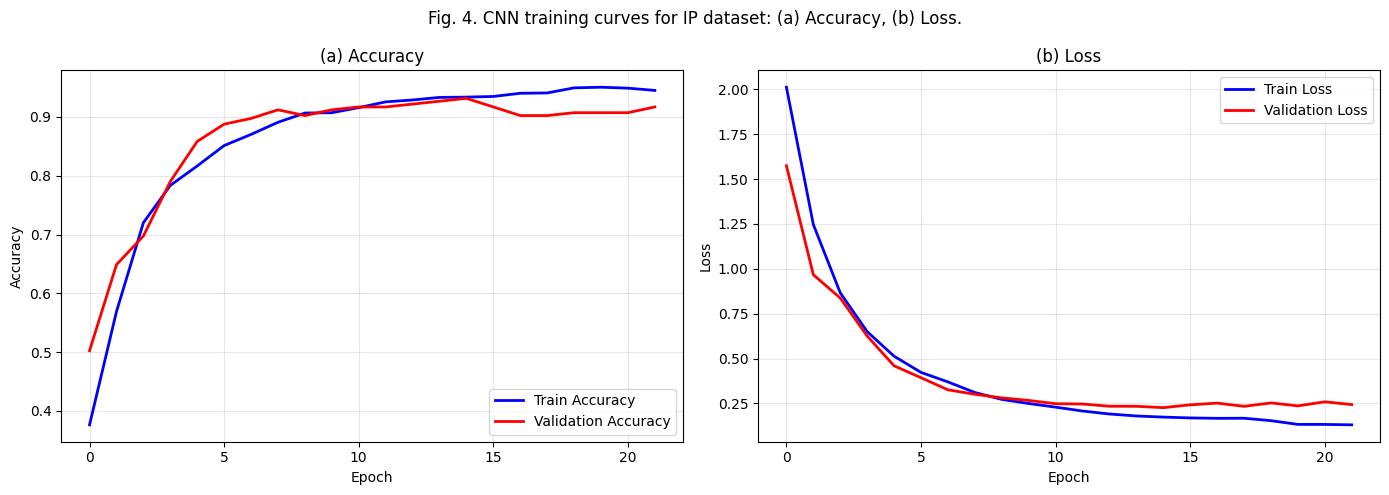

Final Training Loss: 0.1306 | Final Validation Loss: 0.2434
Read-out: High variance (possible overfitting) — val loss notably above train loss.


In [29]:
# --- Fig. 4: Accuracy & Loss curves + bias-variance read-out ---------------
def plot_training_history(history):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(history.history['accuracy'], label='Train Accuracy', color='blue', lw=2)
    ax1.plot(history.history['val_accuracy'], label='Validation Accuracy', color='red', lw=2)
    ax1.set_title('(a) Accuracy'); ax1.set_xlabel('Epoch'); ax1.set_ylabel('Accuracy')
    ax1.legend(); ax1.grid(True, alpha=0.3)

    ax2.plot(history.history['loss'], label='Train Loss', color='blue', lw=2)
    ax2.plot(history.history['val_loss'], label='Validation Loss', color='red', lw=2)
    ax2.set_title('(b) Loss'); ax2.set_xlabel('Epoch'); ax2.set_ylabel('Loss')
    ax2.legend(); ax2.grid(True, alpha=0.3)

    fig.suptitle(f"Fig. 4. CNN training curves for {DATASET} dataset: (a) Accuracy, (b) Loss.")
    plt.tight_layout()
    plt.show()

    train_loss, val_loss = history.history['loss'][-1], history.history['val_loss'][-1]
    print(f"Final Training Loss: {train_loss:.4f} | Final Validation Loss: {val_loss:.4f}")
    if train_loss > 0.5:
        print("Read-out: High bias (possible underfitting) — model may be too simple / undertrained.")
    elif val_loss > train_loss + 0.1:
        print("Read-out: High variance (possible overfitting) — val loss notably above train loss.")
    else:
        print("Read-out: Balanced — train/val losses are close and low.")

plot_training_history(history)

## 10. Deep Feature Extraction

In [30]:
# --- Pull the 128-d 'features' layer out as a standalone feature extractor -
feature_extractor = models.Model(inputs=cnn_model.input, outputs=cnn_model.get_layer('features').output)
train_features = feature_extractor.predict(train_patches, verbose=0)
test_features = feature_extractor.predict(test_patches, verbose=0)
print(f"Deep features: Train {train_features.shape}, Test {test_features.shape}")

Deep features: Train (2049, 128), Test (8200, 128)


## 11. Metaheuristic Feature Selection (PSO & GWO) — Table VI, Figs. 5 & 6
Both optimizers are run (not just whichever `OPTIMIZER` points to) so Table VI and Figures 5/6 can be
built from real numbers on both sides rather than guessed.

In [31]:
# --- Shared helpers ------------------------------------------------------
def _mask_from_solution(solution, min_features=5):
    n_features = len(solution)
    mask = solution > 0.5
    if mask.sum() < min_features:
        top_idx = np.argsort(solution)[::-1][:min_features]
        mask = np.zeros(n_features, dtype=bool)
        mask[top_idx] = True
        print(f"WARNING: optimizer selected < {min_features} features; falling back to top {min_features} by score.")
    return np.where(mask)[0]

def _make_fitness_fn(X_train, y_train):
    classifier = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
    def fitness(solution):
        mask = solution > 0.5
        if np.sum(mask) == 0:
            return 0.0
        X_sel = X_train[:, mask]
        scores = cross_val_score(classifier, X_sel, y_train, cv=5, n_jobs=-1)
        return scores.mean()
    return fitness

def pso_feature_selection(X_train, y_train, pop_size=30, epochs=5, min_features=5,
                           w=0.7, c1=1.5, c2=1.5, seed=RANDOM_STATE):
    """Standard PSO with inertia weight, positions clipped to [0,1]."""
    n_features = X_train.shape[1]
    rng = np.random.RandomState(seed)
    fitness = _make_fitness_fn(X_train, y_train)

    positions = rng.uniform(0, 1, size=(pop_size, n_features))
    velocities = rng.uniform(-0.1, 0.1, size=(pop_size, n_features))
    pbest_pos = positions.copy()
    pbest_fit = np.array([fitness(p) for p in positions])

    gbest_idx = int(np.argmax(pbest_fit))
    gbest_pos = pbest_pos[gbest_idx].copy()
    gbest_fit = pbest_fit[gbest_idx]
    convergence = [gbest_fit]
    print(f"  [PSO] epoch 0/{epochs} best CV accuracy: {gbest_fit:.4f}")

    for epoch in range(1, epochs + 1):
        for i in range(pop_size):
            r1, r2 = rng.rand(n_features), rng.rand(n_features)
            velocities[i] = (w * velocities[i]
                              + c1 * r1 * (pbest_pos[i] - positions[i])
                              + c2 * r2 * (gbest_pos - positions[i]))
            positions[i] = np.clip(positions[i] + velocities[i], 0.0, 1.0)
            fit = fitness(positions[i])
            if fit > pbest_fit[i]:
                pbest_fit[i] = fit
                pbest_pos[i] = positions[i].copy()
                if fit > gbest_fit:
                    gbest_fit = fit
                    gbest_pos = positions[i].copy()
        convergence.append(gbest_fit)
        print(f"  [PSO] epoch {epoch}/{epochs} best CV accuracy: {gbest_fit:.4f}")

    return _mask_from_solution(gbest_pos, min_features), convergence

def gwo_feature_selection(X_train, y_train, pop_size=30, epochs=5, min_features=5, seed=RANDOM_STATE):
    """Standard Grey Wolf Optimizer (alpha/beta/delta guided search)."""
    n_features = X_train.shape[1]
    rng = np.random.RandomState(seed)
    fitness = _make_fitness_fn(X_train, y_train)

    positions = rng.uniform(0, 1, size=(pop_size, n_features))
    fitness_vals = np.array([fitness(p) for p in positions])

    def top3(fvals, pos):
        idx = np.argsort(fvals)[::-1][:3]
        return (pos[idx[0]].copy(), fvals[idx[0]], pos[idx[1]].copy(), fvals[idx[1]],
                pos[idx[2]].copy(), fvals[idx[2]])

    alpha_pos, alpha_fit, beta_pos, beta_fit, delta_pos, delta_fit = top3(fitness_vals, positions)
    convergence = [alpha_fit]
    print(f"  [GWO] epoch 0/{epochs} best CV accuracy: {alpha_fit:.4f}")

    for epoch in range(1, epochs + 1):
        a = 2.0 - epoch * (2.0 / epochs)
        for i in range(pop_size):
            A1 = 2 * a * rng.rand(n_features) - a; C1 = 2 * rng.rand(n_features)
            X1 = alpha_pos - A1 * np.abs(C1 * alpha_pos - positions[i])
            A2 = 2 * a * rng.rand(n_features) - a; C2 = 2 * rng.rand(n_features)
            X2 = beta_pos - A2 * np.abs(C2 * beta_pos - positions[i])
            A3 = 2 * a * rng.rand(n_features) - a; C3 = 2 * rng.rand(n_features)
            X3 = delta_pos - A3 * np.abs(C3 * delta_pos - positions[i])
            positions[i] = np.clip((X1 + X2 + X3) / 3.0, 0.0, 1.0)
            fitness_vals[i] = fitness(positions[i])
        alpha_pos, alpha_fit, beta_pos, beta_fit, delta_pos, delta_fit = top3(fitness_vals, positions)
        convergence.append(alpha_fit)
        print(f"  [GWO] epoch {epoch}/{epochs} best CV accuracy: {alpha_fit:.4f}")

    return _mask_from_solution(alpha_pos, min_features), convergence

In [33]:
# --- Run PSO ---------------------------------------------------------
_opt_epochs = 3 if USE_SYNTHETIC_DEMO_DATA else EPOCHS_OPT
_opt_pop = 10 if USE_SYNTHETIC_DEMO_DATA else POP_SIZE_OPT

pso_indices, pso_convergence = pso_feature_selection(
    train_features, y_train, pop_size=_opt_pop, epochs=_opt_epochs
)
print(f"\nPSO selected {len(pso_indices)} / {train_features.shape[1]} features.")

  [PSO] epoch 0/5 best CV accuracy: 0.9697
  [PSO] epoch 1/5 best CV accuracy: 0.9697
  [PSO] epoch 2/5 best CV accuracy: 0.9712
  [PSO] epoch 3/5 best CV accuracy: 0.9717
  [PSO] epoch 4/5 best CV accuracy: 0.9717
  [PSO] epoch 5/5 best CV accuracy: 0.9717

PSO selected 61 / 128 features.


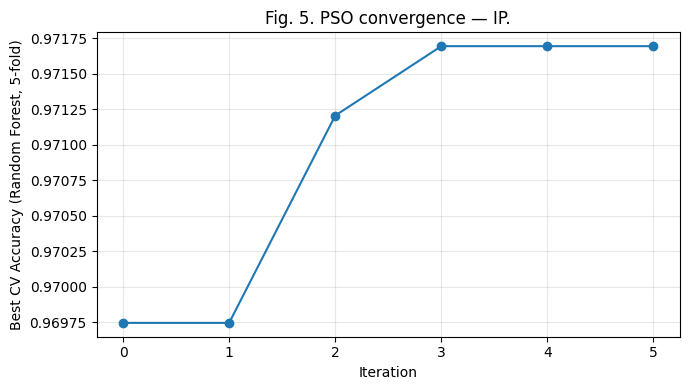

In [34]:
# --- Fig. 5: PSO convergence curve -----------------------------------
plt.figure(figsize=(7, 4))
plt.plot(range(len(pso_convergence)), pso_convergence, marker='o', color='tab:blue')
plt.xlabel("Iteration"); plt.ylabel("Best CV Accuracy (Random Forest, 5-fold)")
plt.title(f"Fig. 5. PSO convergence — {DATASET}.")
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

In [35]:
# --- Run GWO -----------------------------------------------------------
gwo_indices, gwo_convergence = gwo_feature_selection(
    train_features, y_train, pop_size=_opt_pop, epochs=_opt_epochs
)
print(f"\nGWO selected {len(gwo_indices)} / {train_features.shape[1]} features.")

  [GWO] epoch 0/5 best CV accuracy: 0.9697
  [GWO] epoch 1/5 best CV accuracy: 0.9717
  [GWO] epoch 2/5 best CV accuracy: 0.9697
  [GWO] epoch 3/5 best CV accuracy: 0.9732
  [GWO] epoch 4/5 best CV accuracy: 0.9693
  [GWO] epoch 5/5 best CV accuracy: 0.9644

GWO selected 69 / 128 features.


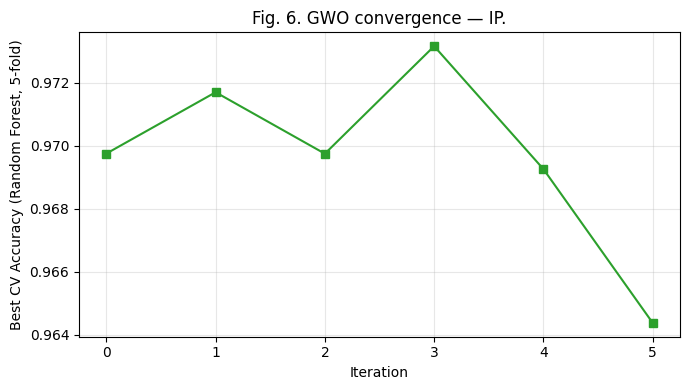

In [36]:
# --- Fig. 6: GWO convergence curve -------------------------------------
plt.figure(figsize=(7, 4))
plt.plot(range(len(gwo_convergence)), gwo_convergence, marker='s', color='tab:green')
plt.xlabel("Iteration"); plt.ylabel("Best CV Accuracy (Random Forest, 5-fold)")
plt.title(f"Fig. 6. GWO convergence — {DATASET}.")
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

In [37]:
# --- TABLE VI: Feature Selection Summary (computed, not guessed) ----------
total_feats = train_features.shape[1]
table6 = pd.DataFrame([{
    "Dataset": DATASET,
    "Total Features (from CNN)": total_feats,
    "PSO Selected Features": len(pso_indices),
    "GWO Selected Features": len(gwo_indices),
    "PSO Reduction %": f"{100*(1 - len(pso_indices)/total_feats):.2f}%",
    "GWO Reduction %": f"{100*(1 - len(gwo_indices)/total_feats):.2f}%",
}])
print("TABLE VI: FEATURE SELECTION RESULTS")
print(table6.to_string(index=False))
table6

TABLE VI: FEATURE SELECTION RESULTS
Dataset  Total Features (from CNN)  PSO Selected Features  GWO Selected Features PSO Reduction % GWO Reduction %
     IP                        128                     61                     69          52.34%          46.09%


,Dataset,Total Features (from CNN),PSO Selected Features,GWO Selected Features,PSO Reduction %,GWO Reduction %
0,IP,128,61,69,52.34%,46.09%


## 12. Classifier Comparison — Table VII

In [38]:
# --- Classifier registry + evaluation ------------------------------------
def get_classifiers():
    return {
        "KNN": KNeighborsClassifier(n_neighbors=5),
        "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
        "Logistic Regression": LogisticRegression(solver='lbfgs', max_iter=2000, random_state=RANDOM_STATE),  # lbfgs: liblinear dropped native multiclass support
        "AdaBoost": AdaBoostClassifier(n_estimators=50, random_state=RANDOM_STATE),
        "XGBoost": XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=6, random_state=RANDOM_STATE),
        "Gaussian NB": GaussianNB(),
        "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=RANDOM_STATE),
    }

def evaluate_all_classifiers(X_train_sel, X_test_sel, y_train, y_test):
    """Labels are shifted to 0-index for classifiers that need it (XGBoost),
    then shifted back before scoring so metrics stay in the original label space."""
    classifiers = get_classifiers()
    results = []
    y_train_adj, y_test_adj = y_train - 1, y_test - 1

    for name, clf in classifiers.items():
        t0 = time.time(); clf.fit(X_train_sel, y_train_adj); train_time = time.time() - t0
        t0 = time.time(); y_pred = clf.predict(X_test_sel); test_time = time.time() - t0
        y_pred_final = y_pred + 1

        OA = accuracy_score(y_test, y_pred_final)
        Kappa = cohen_kappa_score(y_test, y_pred_final)
        precision = precision_score(y_test, y_pred_final, average='macro', zero_division=0)
        recall = recall_score(y_test, y_pred_final, average='macro', zero_division=0)
        f1 = f1_score(y_test, y_pred_final, average='macro', zero_division=0)
        class_acc = [accuracy_score(y_test[y_test == c], y_pred_final[y_test == c]) for c in np.unique(y_test)]
        AA = np.mean(class_acc) * 100

        results.append((name, OA*100, AA, Kappa*100, precision*100, recall*100, f1*100,
                         train_time, test_time, y_pred_final))
        print(f"{name:20s} | OA: {OA*100:6.2f}% | AA: {AA:6.2f}% | K: {Kappa*100:6.2f}% | "
              f"P: {precision*100:6.2f}% | R: {recall*100:6.2f}% | F1: {f1*100:6.2f}% | "
              f"Train: {train_time:.3f}s | Test: {test_time:.3f}s")
    return results

In [39]:
# --- Run classifiers on the PSO-selected features --------------------------
X_train_sel = train_features[:, pso_indices]
X_test_sel = test_features[:, pso_indices]

print(f"=== Classifier comparison on {DATASET} (features selected by PSO) ===")
print("-" * 130)
results = evaluate_all_classifiers(X_train_sel, X_test_sel, y_train, y_test)

=== Classifier comparison on IP (features selected by PSO) ===
----------------------------------------------------------------------------------------------------------------------------------
KNN                  | OA:  96.28% | AA:  89.23% | K:  95.76% | P:  95.61% | R:  89.23% | F1:  90.58% | Train: 0.001s | Test: 0.168s
Random Forest        | OA:  97.44% | AA:  94.09% | K:  97.08% | P:  97.56% | R:  94.09% | F1:  95.68% | Train: 0.870s | Test: 0.086s
Logistic Regression  | OA:  97.22% | AA:  93.97% | K:  96.83% | P:  97.08% | R:  93.97% | F1:  95.36% | Train: 9.206s | Test: 0.018s
AdaBoost             | OA:  44.88% | AA:  21.88% | K:  31.82% | P:  36.28% | R:  21.88% | F1:  20.71% | Train: 0.832s | Test: 0.057s
XGBoost              | OA:  96.72% | AA:  92.22% | K:  96.26% | P:  94.79% | R:  92.22% | F1:  93.40% | Train: 3.317s | Test: 0.140s
Gaussian NB          | OA:  76.98% | AA:  84.24% | K:  74.22% | P:  73.53% | R:  84.24% | F1:  76.68% | Train: 0.003s | Test: 0.029s
Extra Tr

In [40]:
# --- TABLE VII: full classifier comparison table ---------------------------
table7 = pd.DataFrame(results, columns=['Classifier', 'OA', 'AA', 'Kappa', 'Precision',
                                          'Recall', 'F1', 'Train_Time', 'Test_Time', 'y_pred'])
table7_display = table7.drop(columns=['y_pred']).round(2)
print("TABLE VII: CLASSIFIER COMPARISON (PSO-selected features)")
print(table7_display.to_string(index=False))

table7_display.to_excel(f"{DATASET}_{OPTIMIZER}_classifier_results.xlsx", index=False)
print(f"\nSaved to {DATASET}_{OPTIMIZER}_classifier_results.xlsx")
table7_display

TABLE VII: CLASSIFIER COMPARISON (PSO-selected features)
         Classifier    OA    AA  Kappa  Precision  Recall    F1  Train_Time  Test_Time
                KNN 96.28 89.23  95.76      95.61   89.23 90.58        0.00       0.17
      Random Forest 97.44 94.09  97.08      97.56   94.09 95.68        0.87       0.09
Logistic Regression 97.22 93.97  96.83      97.08   93.97 95.36        9.21       0.02
           AdaBoost 44.88 21.88  31.82      36.28   21.88 20.71        0.83       0.06
            XGBoost 96.72 92.22  96.26      94.79   92.22 93.40        3.32       0.14
        Gaussian NB 76.98 84.24  74.22      73.53   84.24 76.68        0.00       0.03
        Extra Trees 98.30 95.82  98.07      98.34   95.82 96.98        0.27       0.10

Saved to IP_GWO_classifier_results.xlsx


,Classifier,OA,AA,Kappa,Precision,Recall,F1,Train_Time,Test_Time
0,KNN,96.28,89.23,95.76,95.61,89.23,90.58,0.00,0.17
1,Random Forest,97.44,94.09,97.08,97.56,94.09,95.68,0.87,0.09
2,Logistic Regression,97.22,93.97,96.83,97.08,93.97,95.36,9.21,0.02
3,AdaBoost,44.88,21.88,31.82,36.28,21.88,20.71,0.83,0.06
4,XGBoost,96.72,92.22,96.26,94.79,92.22,93.40,3.32,0.14
5,Gaussian NB,76.98,84.24,74.22,73.53,84.24,76.68,0.00,0.03
6,Extra Trees,98.30,95.82,98.07,98.34,95.82,96.98,0.27,0.10


## 13. Baseline vs. Proposed — Table VIII & Fig. 10

In [41]:
# --- Baseline: all 128 CNN features (no metaheuristic selection) + RF ------
t0 = time.time()
rf_baseline = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
rf_baseline.fit(train_features, y_train - 1)
baseline_train_time = time.time() - t0

t0 = time.time()
y_pred_baseline = rf_baseline.predict(test_features) + 1
baseline_test_time = time.time() - t0

baseline_OA = accuracy_score(y_test, y_pred_baseline) * 100
print(f"Baseline (CNN features + RF, no selection): OA = {baseline_OA:.2f}%, "
      f"train = {baseline_train_time:.3f}s, test = {baseline_test_time:.3f}s")

Baseline (CNN features + RF, no selection): OA = 97.33%, train = 1.265s, test = 0.076s


In [42]:
# --- TABLE VIII: Baseline vs Proposed ---------------------------------------
et_row = table7[table7['Classifier'] == 'Extra Trees'].iloc[0]

table8 = pd.DataFrame([
    {"Method": "CNN Features + RF (Baseline)", f"{DATASET} OA (%)": round(baseline_OA, 2),
     "Training Time (s)": round(baseline_train_time, 3), "Testing Time (s)": round(baseline_test_time, 3)},
    {"Method": "CNN + PSO + RF", f"{DATASET} OA (%)": round(table7[table7['Classifier']=='Random Forest']['OA'].iloc[0], 2),
     "Training Time (s)": round(table7[table7['Classifier']=='Random Forest']['Train_Time'].iloc[0], 3),
     "Testing Time (s)": round(table7[table7['Classifier']=='Random Forest']['Test_Time'].iloc[0], 3)},
    {"Method": "CNN + PSO + Extra Trees", f"{DATASET} OA (%)": round(et_row['OA'], 2),
     "Training Time (s)": round(et_row['Train_Time'], 3), "Testing Time (s)": round(et_row['Test_Time'], 3)},
])
print("TABLE VIII: BASELINE VS PROPOSED (this run; add GWO/SA/PU rows the same way)")
print(table8.to_string(index=False))
table8

TABLE VIII: BASELINE VS PROPOSED (this run; add GWO/SA/PU rows the same way)
                      Method  IP OA (%)  Training Time (s)  Testing Time (s)
CNN Features + RF (Baseline)      97.33              1.265             0.076
              CNN + PSO + RF      97.44              0.870             0.086
     CNN + PSO + Extra Trees      98.30              0.271             0.102


,Method,IP OA (%),Training Time (s),Testing Time (s)
0,CNN Features + RF (Baseline),97.33,1.265,0.076
1,CNN + PSO + RF,97.44,0.870,0.086
2,CNN + PSO + Extra Trees,98.30,0.271,0.102


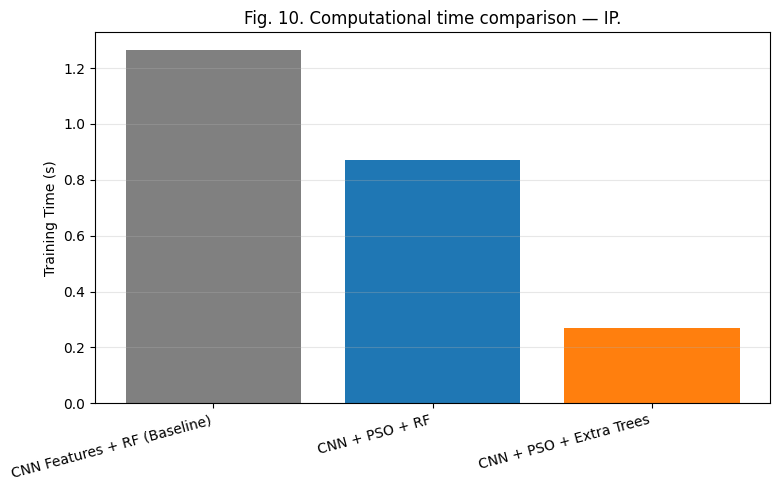

In [43]:
# --- Fig. 10: Computational time comparison bar chart -----------------------
methods = table8["Method"].tolist()
train_times = table8["Training Time (s)"].tolist()

plt.figure(figsize=(8, 5))
plt.bar(methods, train_times, color=['gray', 'tab:blue', 'tab:orange'])
plt.ylabel("Training Time (s)")
plt.title(f"Fig. 10. Computational time comparison — {DATASET}.")
plt.xticks(rotation=15, ha='right')
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 14. Fig. 7 — Confusion Matrix (Best Classifier)

Best classifier by OA: Extra Trees (98.30%)


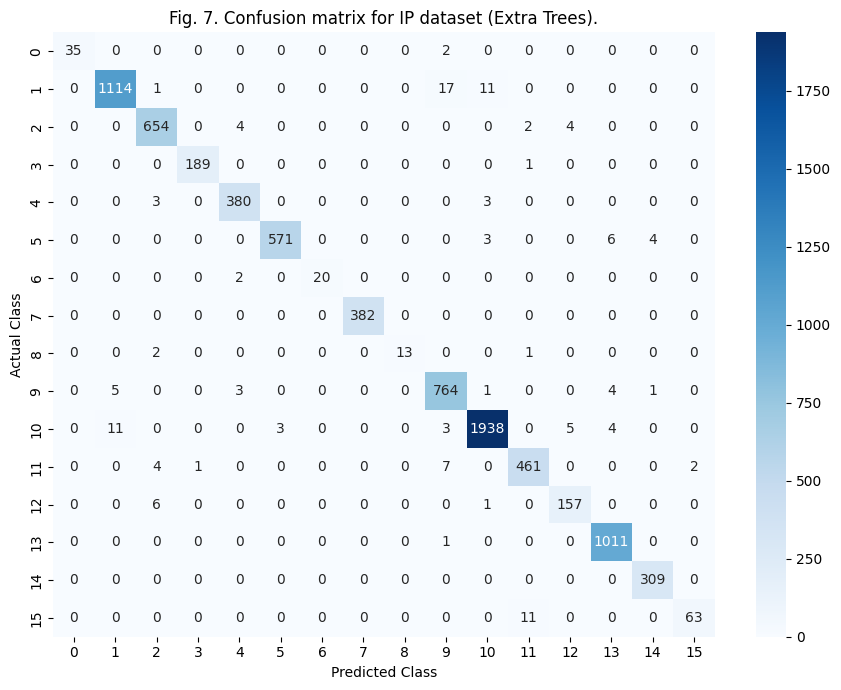

In [44]:
# --- Fig. 7: confusion matrix for the best classifier (highest OA) -------
best_row = table7.loc[table7['OA'].idxmax()]
best_clf_name, y_pred_best = best_row['Classifier'], best_row['y_pred']
print(f"Best classifier by OA: {best_clf_name} ({best_row['OA']:.2f}%)")

def plot_ieee_cm(y_true, y_pred, dataset_name, clf_name):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(9, 7))
    sns.heatmap(cm, annot=cm.shape[0] <= 20, fmt='d', cmap='Blues', cbar=True)
    plt.title(f"Fig. 7. Confusion matrix for {dataset_name} dataset ({clf_name}).")
    plt.ylabel('Actual Class'); plt.xlabel('Predicted Class')
    plt.tight_layout(); plt.show()

plot_ieee_cm(y_test, y_pred_best, DATASET, best_clf_name)

## 15. Fig. 8 — Classification Maps (Ground Truth vs. Predicted)

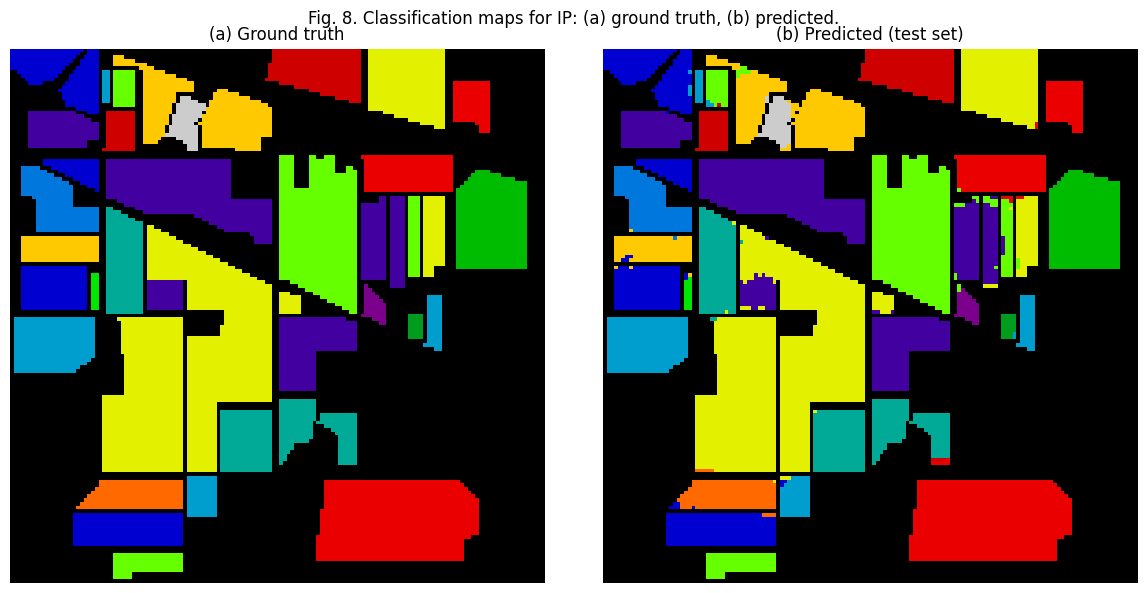

In [45]:
# --- Fig. 8: ground truth vs predicted classification map ------------------
def plot_classification_maps(labels, train_coords, test_coords, y_pred, H, W, dataset_name):
    gt_map = labels.copy()
    pred_map = np.zeros((H, W))
    for (r, c) in train_coords:
        pred_map[r, c] = labels[r, c]  # show train pixels at their true label too
    for (r, c), p in zip(test_coords, y_pred):
        pred_map[r, c] = p

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    axes[0].imshow(gt_map, cmap='nipy_spectral'); axes[0].set_title("(a) Ground truth"); axes[0].axis('off')
    axes[1].imshow(pred_map, cmap='nipy_spectral'); axes[1].set_title("(b) Predicted (test set)"); axes[1].axis('off')
    fig.suptitle(f"Fig. 8. Classification maps for {dataset_name}: (a) ground truth, (b) predicted.")
    plt.tight_layout(); plt.show()

plot_classification_maps(labels, train_coords, test_coords, y_pred_best, H, W, DATASET)

## 16. Fig. 9 — Class-wise Accuracy

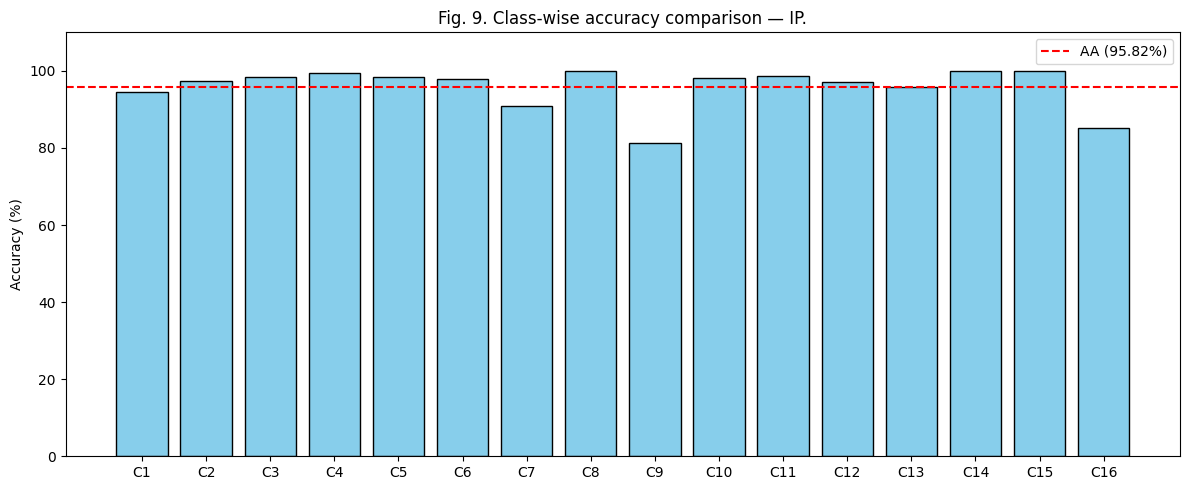

In [46]:
# --- Fig. 9: class-wise accuracy bar chart ---------------------------------
def plot_class_accuracy(y_true, y_pred, dataset_name):
    classes = np.unique(y_true)
    accs = [accuracy_score(y_true[y_true == c], y_pred[y_true == c]) * 100 for c in classes]
    plt.figure(figsize=(12, 5))
    plt.bar([f'C{int(c)}' for c in classes], accs, color='skyblue', edgecolor='black')
    plt.axhline(y=np.mean(accs), color='r', linestyle='--', label=f'AA ({np.mean(accs):.2f}%)')
    plt.title(f"Fig. 9. Class-wise accuracy comparison — {dataset_name}.")
    plt.ylabel('Accuracy (%)'); plt.ylim(0, 110); plt.legend()
    plt.tight_layout(); plt.show()

plot_class_accuracy(y_test, y_pred_best, DATASET)

## 17. Fig. 1 — Proposed Framework (Pipeline Diagram)
Drawn from scratch (no data dependency) so it always renders the same, regardless of demo/real mode.

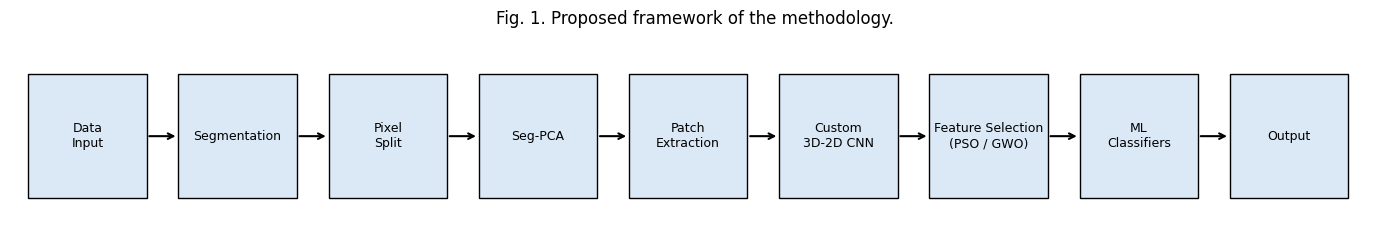

In [47]:
# --- Fig. 1: pipeline block diagram -----------------------------------
def plot_pipeline_diagram():
    stages = ["Data\nInput", "Segmentation", "Pixel\nSplit", "Seg-PCA", "Patch\nExtraction",
              "Custom\n3D-2D CNN", "Feature Selection\n(PSO / GWO)", "ML\nClassifiers", "Output"]
    fig, ax = plt.subplots(figsize=(14, 2.6))
    n = len(stages)
    box_w, box_h, gap = 1.3, 0.9, 0.35
    for i, label in enumerate(stages):
        x = i * (box_w + gap)
        ax.add_patch(plt.Rectangle((x, 0), box_w, box_h, facecolor='#dbe9f6', edgecolor='black'))
        ax.text(x + box_w/2, box_h/2, label, ha='center', va='center', fontsize=9)
        if i < n - 1:
            ax.annotate("", xy=(x + box_w + gap, box_h/2), xytext=(x + box_w, box_h/2),
                        arrowprops=dict(arrowstyle="->", lw=1.5))
    ax.set_xlim(-0.2, n * (box_w + gap))
    ax.set_ylim(-0.3, box_h + 0.3)
    ax.axis('off')
    ax.set_title("Fig. 1. Proposed framework of the methodology.")
    plt.tight_layout()
    plt.show()

plot_pipeline_diagram()

## 18. Table IX — State-of-the-Art Comparison
Only your own "Proposed" row can be computed from this run; every other row is a **literature value you
must supply from the papers you're citing** — edit the `literature_rows` list below with your real sources.
(The starting numbers below are the ones you already had queued up — replace/verify against your actual
citations before submitting.)

In [48]:
# --- TABLE IX: SOTA comparison (literature rows are manual; Proposed row is computed) ---
literature_rows = [
    {"Method": "SVM (Spectral)", "IP OA (%)": 46, "SA OA (%)": 70, "PU OA (%)": 62},
    {"Method": "2D-CNN", "IP OA (%)": 87, "SA OA (%)": 98, "PU OA (%)": 99},
    {"Method": "HybridSN", "IP OA (%)": 99.1, "SA OA (%)": 99.9, "PU OA (%)": 99.9},
    {"Method": "3D-2D Multibranch (Paper 1)", "IP OA (%)": 99.27, "SA OA (%)": 100, "PU OA (%)": 99.99},
    {"Method": "Seg-PCA + 3D-2D CNN (Paper 2)", "IP OA (%)": 99.06, "SA OA (%)": 100, "PU OA (%)": 99.94},
    {"Method": "SPCA + mRMR + 3D-2D CNN (Paper 3)", "IP OA (%)": 99.12, "SA OA (%)": 100, "PU OA (%)": 99.94},
    {"Method": "VGG19 + PSO + RF (Paper 4)", "IP OA (%)": 100, "SA OA (%)": 100, "PU OA (%)": 100},
]

proposed_row = {"Method": "Proposed (Custom CNN + PSO + Extra Trees)",
                 f"{DATASET} OA (%)": round(et_row['OA'], 2)}

table9 = pd.concat([pd.DataFrame(literature_rows), pd.DataFrame([proposed_row])], ignore_index=True)
print("TABLE IX: STATE-OF-THE-ART COMPARISON (literature rows need your citations verified)")
print(table9.to_string(index=False))
table9

TABLE IX: STATE-OF-THE-ART COMPARISON (literature rows need your citations verified)
                                   Method  IP OA (%)  SA OA (%)  PU OA (%)
                           SVM (Spectral)      46.00       70.0      62.00
                                   2D-CNN      87.00       98.0      99.00
                                 HybridSN      99.10       99.9      99.90
              3D-2D Multibranch (Paper 1)      99.27      100.0      99.99
            Seg-PCA + 3D-2D CNN (Paper 2)      99.06      100.0      99.94
        SPCA + mRMR + 3D-2D CNN (Paper 3)      99.12      100.0      99.94
               VGG19 + PSO + RF (Paper 4)     100.00      100.0     100.00
Proposed (Custom CNN + PSO + Extra Trees)      98.30        NaN        NaN


,Method,IP OA (%),SA OA (%),PU OA (%)
0,SVM (Spectral),46.00,70.0,62.00
1,2D-CNN,87.00,98.0,99.00
2,HybridSN,99.10,99.9,99.90
3,3D-2D Multibranch (Paper 1),99.27,100.0,99.99
4,Seg-PCA + 3D-2D CNN (Paper 2),99.06,100.0,99.94
5,SPCA + mRMR + 3D-2D CNN (Paper 3),99.12,100.0,99.94
6,VGG19 + PSO + RF (Paper 4),100.00,100.0,100.00
7,Proposed (Custom CNN + PSO + Extra Trees),98.30,NaN,NaN


## 19. Export All Tables (LaTeX / Excel)
Bundles Tables I–IX into one Excel workbook (one sheet per table) plus LaTeX snippets, so you're not
retyping numbers into the paper by hand.

In [49]:
# --- Export every table to one Excel workbook + LaTeX ----------------------
all_tables = {
    "Table_I_Dataset": table1, "Table_II_Segmentation": table2, "Table_III_Variance": table3,
    "Table_IV_CNN_Arch": table4, "Table_V_Training": table5_full, "Table_VI_FeatSelect": table6,
    "Table_VII_Classifiers": table7_display, "Table_VIII_Baseline_vs_Proposed": table8,
    "Table_IX_SOTA": table9,
}
out_path = f"{DATASET}_IEEE_tables.xlsx"
with pd.ExcelWriter(out_path) as writer:
    for name, df in all_tables.items():
        df.to_excel(writer, sheet_name=name[:31], index=False)
print(f"All tables saved to {out_path}")

print("\n--- LaTeX snippet for TABLE VII (paste into your paper) ---")
print(table7_display.to_latex(index=False, float_format="%.2f"))

All tables saved to IP_IEEE_tables.xlsx

--- LaTeX snippet for TABLE VII (paste into your paper) ---
\begin{tabular}{lrrrrrrrr}
\toprule
Classifier & OA & AA & Kappa & Precision & Recall & F1 & Train_Time & Test_Time \\
\midrule
KNN & 96.28 & 89.23 & 95.76 & 95.61 & 89.23 & 90.58 & 0.00 & 0.17 \\
Random Forest & 97.44 & 94.09 & 97.08 & 97.56 & 94.09 & 95.68 & 0.87 & 0.09 \\
Logistic Regression & 97.22 & 93.97 & 96.83 & 97.08 & 93.97 & 95.36 & 9.21 & 0.02 \\
AdaBoost & 44.88 & 21.88 & 31.82 & 36.28 & 21.88 & 20.71 & 0.83 & 0.06 \\
XGBoost & 96.72 & 92.22 & 96.26 & 94.79 & 92.22 & 93.40 & 3.32 & 0.14 \\
Gaussian NB & 76.98 & 84.24 & 74.22 & 73.53 & 84.24 & 76.68 & 0.00 & 0.03 \\
Extra Trees & 98.30 & 95.82 & 98.07 & 98.34 & 95.82 & 96.98 & 0.27 & 0.10 \\
\bottomrule
\end{tabular}



## 20. IEEE Caption Cheat-Sheet
| Type | Caption format |
|---|---|
| Table | `TABLE I: DATASET DESCRIPTION` (all caps, roman numeral) |
| Figure | `Fig. 1. Proposed framework of the methodology.` |
| Sub-figure | `Fig. 4. CNN training curves for IP dataset: (a) Accuracy, (b) Loss.` |

**What to lead with for each purpose:**
- **Main results:** Tables VII, VIII, IX
- **No-leakage evidence:** Figures 3, 5, 6, 10 (+ the split-strategy note in the intro cell)
- **CNN performance:** Figure 4
- **Class-wise performance:** Figures 7, 9
- **Visual proof:** Figure 8
- **Credible positioning vs. literature:** Table IX (once you verify the literature rows)